# Semana 10: Probabilidad y procesos estocásticos: trenes de spikes Poisson

**Objetivo:** distinguir un tren de spikes regular de uno Poisson con la misma tasa media, y
cuantificar la variabilidad entre repeticiones.

## Modelo

Un proceso de Poisson homogéneo de tasa $r$ genera spikes independientes. En una ventana de
duración $T$:

$$P(N = k) = \frac{(rT)^k e^{-rT}}{k!}, \qquad \mathbb{E}[N] = \text{Var}[N] = rT$$

Los intervalos entre spikes (ISI) siguen una exponencial, $p(\Delta) = r\,e^{-r\Delta}$. Dos
medidas de variabilidad:

- **Factor de Fano** $F = \text{Var}[N] / \mathbb{E}[N]$: vale 1 para Poisson y 0 para un tren regular.
- **Coeficiente de variación** de los ISI, $CV = \sigma_\Delta / \mu_\Delta$: vale 1 para Poisson.

Parámetros: $r = 20$ Hz, $T = 2$ s ($rT = 40$ spikes esperados), 200 repeticiones.
Generación: se muestrea $N \sim \text{Poisson}(rT)$ y se reparten $N$ tiempos uniformes en $[0, T]$.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 10
RATE_HZ = 20.0
DURATION_S = 2.0
TRIALS = 200
rng = np.random.default_rng(10)

regular = np.arange(1.0 / RATE_HZ, DURATION_S, 1.0 / RATE_HZ)
trials = [np.sort(rng.uniform(0.0, DURATION_S, rng.poisson(RATE_HZ * DURATION_S))) for _ in range(TRIALS)]
counts = np.array([spikes.size for spikes in trials])
intervals = np.concatenate([np.diff(spikes) for spikes in trials])
fano = counts.var(ddof=1) / counts.mean()
cv = intervals.std(ddof=1) / intervals.mean()

## Figura

Izquierda: tren regular (arriba, negro) y 15 repeticiones Poisson. Centro: histograma de conteos
en las 200 repeticiones frente a la distribución de Poisson teórica. Derecha: histograma de ISI
frente a la densidad exponencial.

Saved: weeks/week_10_stochastic_spikes/outputs/stochastic_spikes.png
Saved: weeks/week_10_stochastic_spikes/outputs/stochastic_spikes.npz


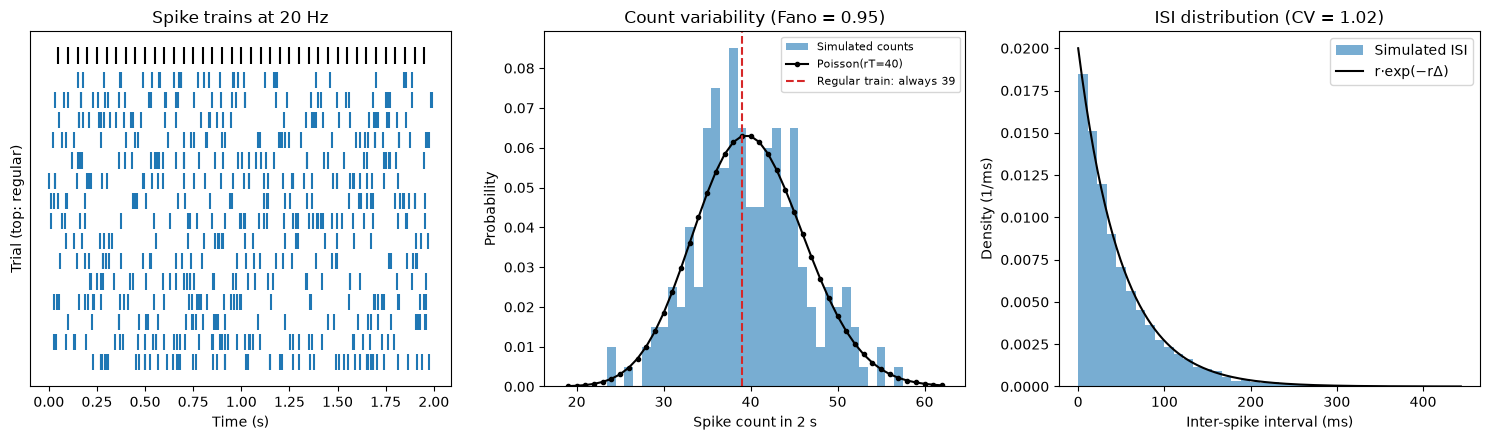

In [2]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].vlines(regular, 15.2, 16.0, color="black")
for row, spikes in enumerate(trials[:15]):
    axes[0].vlines(spikes, row, row + 0.8)
axes[0].set(xlabel="Time (s)", ylabel="Trial (top: regular)", yticks=[], title=f"Spike trains at {RATE_HZ:g} Hz")

k = np.arange(counts.min() - 5, counts.max() + 6)
poisson_pmf = np.array([math.exp(-RATE_HZ * DURATION_S) * (RATE_HZ * DURATION_S) ** int(value) / math.factorial(int(value)) for value in k])
axes[1].hist(counts, bins=np.arange(k[0] - 0.5, k[-1] + 1.5), density=True, alpha=0.6, label="Simulated counts")
axes[1].plot(k, poisson_pmf, "k.-", label=f"Poisson(rT={RATE_HZ * DURATION_S:g})")
axes[1].axvline(regular.size, color="tab:red", linestyle="--", label=f"Regular train: always {regular.size}")
axes[1].set(xlabel="Spike count in 2 s", ylabel="Probability", title=f"Count variability (Fano = {fano:.2f})")
axes[1].legend(fontsize=8)

grid = np.linspace(0.0, intervals.max(), 200)
axes[2].hist(intervals * 1000, bins=40, density=True, alpha=0.6, label="Simulated ISI")
axes[2].plot(grid * 1000, RATE_HZ * np.exp(-RATE_HZ * grid) / 1000, "k-", label="r·exp(−rΔ)")
axes[2].set(xlabel="Inter-spike interval (ms)", ylabel="Density (1/ms)", title=f"ISI distribution (CV = {cv:.2f})")
axes[2].legend()
save_figure(WEEK, figure, "stochastic_spikes.png")
save_data(WEEK, "stochastic_spikes.npz", regular_spikes_s=regular, poisson_counts=counts, intervals_s=intervals,
          fano_factor=np.array(fano), isi_cv=np.array(cv))

## Validación

- El conteo medio está cerca de $rT = 40$.
- Fano y CV están cerca de 1 (Poisson); el tren regular tiene Fano 0.
- El ISI medio está cerca de $1/r = 50$ ms.

In [3]:
assert abs(counts.mean() - RATE_HZ * DURATION_S) < 2.0
assert 0.8 < fano < 1.2, fano
assert 0.9 < cv < 1.1, cv
assert abs(intervals.mean() - 1.0 / RATE_HZ) < 0.005
print(f"Mean count {counts.mean():.1f} (expected 40), Fano {fano:.2f}, ISI CV {cv:.2f}, mean ISI {intervals.mean() * 1000:.1f} ms")
print(f"Single trial counts range from {counts.min()} to {counts.max()}")

Mean count 39.9 (expected 40), Fano 0.95, ISI CV 1.02, mean ISI 48.7 ms
Single trial counts range from 24 to 57


## Interpretación y límites

- Una sola repetición puede tener entre ~25 y ~55 spikes con la misma tasa verdadera: no basta
  para estimar la tasa ni su variabilidad.
- Neuronas reales tienen período refractario (CV < 1 a tasas altas) y a menudo sobredispersión
  (Fano > 1) por cambios lentos de excitabilidad; Poisson es un modelo de referencia.

**Para tu entrega:** añade un período refractario de 5 ms eliminando ISI más cortos, y explica
cómo cambian el CV y el factor de Fano.